# Split one template into two rank-1 atoms

Uses [`split_one_template`](../code/learn/split_template.py) via the experiment helper
[`run_split`](../experiments/split_one_template.py):

1. Start from the unit-normalized dictionary word $v$.
2. For each of **K** trials: draw $\varepsilon$ with $\|\varepsilon\| = \texttt{epsilon}\cdot\|v\|$, form $v\pm\varepsilon$, assign patches by explained energy, then run up to **S** PC1-refit / reassignment steps.
3. Keep the trial with the smallest residual SSE.

Displays the **original** template, the two **child** templates (unit L2), and the **patches** assigned to each child.

Color scale: each array is L2-normalized, then shown with **jet** and symmetric limits $\pm P_{90}(|\cdot|)$ so sparse spikes do not wash out the figure.


In [1]:
%matplotlib inline

import sys
from contextlib import closing
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display

REPO = Path("/home/yfreund/projects/gplrev3-webserver")
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

from database import catalog
from analysis.dict_learning.code.core.objects import Matching
from analysis.dict_learning.code.io.io_gpl import load_windows_from_paths
from analysis.dict_learning.code.learn.extend_dictionary import load_dictionary_from_catalog
from analysis.dict_learning.code.learn.seed_from_gpl import mean_center
from analysis.dict_learning.code.tools import _extract_patches
from analysis.dict_learning.experiments.split_one_template import run_split

LIBRARY_ROOT = Path("/home/yfreund/whale_processing")
DB_PATH = LIBRARY_ROOT / "result/dict_learning_catalog.sqlite"

DICTIONARY_ID: int | None = 115
TEMPLATE_ID: int | None = None  # None → template with the most matchings

N_TRIALS = 20          # K: random ±ε restarts; keep best SSE
N_REFINE = 3           # S: assign→PC1 refine iterations per trial
EPSILON = 0.1          # ||ε|| = EPSILON * ||v||
MIN_SIZE = 2
RNG_SEED = 0

MAX_PATCHES_SHOWN = None  # None → show every patch; or set an int cap
PANEL_W = 0.85
PANEL_H = 5.0 * PANEL_W  # height:width = 5:1 for template row
PATCH_PANEL_W = 1.1       # slightly wider panels in patch galleries
PATCH_NCOLS = 4


## Load dictionary, windows, and patches

In [2]:
with closing(catalog.connect(DB_PATH, read_only=True)) as conn:
    if DICTIONARY_ID is None:
        row = conn.execute(
            "SELECT dictionary_id, name, parent_dictionary_id, created_at "
            "FROM dictionaries ORDER BY dictionary_id DESC LIMIT 1"
        ).fetchone()
        dictionary_id = int(row["dictionary_id"])
        dict_meta = dict(row)
    else:
        dictionary_id = int(DICTIONARY_ID)
        dict_meta = catalog.get_dictionary(conn, dictionary_id)
        if dict_meta is None:
            raise ValueError(f"dictionary_id={dictionary_id} not found")

    dictionary = load_dictionary_from_catalog(conn, dictionary_id)
    counts = conn.execute(
        """
        SELECT t.template_id, COUNT(*) AS n
        FROM matchings m
        JOIN templates t ON t.template_pk = m.template_pk
        WHERE m.dictionary_id = ?
        GROUP BY t.template_id
        ORDER BY n DESC, t.template_id
        """,
        (dictionary_id,),
    ).fetchall()
    count_map = {int(r["template_id"]): int(r["n"]) for r in counts}

    if TEMPLATE_ID is None:
        if not counts:
            raise RuntimeError(f"dictionary {dictionary_id} has no matchings")
        template_id = int(counts[0]["template_id"])
    else:
        template_id = int(TEMPLATE_ID)

    matching_rows = conn.execute(
        """
        SELECT m.window_id, m.t_start, m.amplitude, t.template_id
        FROM matchings m
        JOIN templates t ON t.template_pk = m.template_pk
        WHERE m.dictionary_id = ? AND t.template_id = ?
        ORDER BY m.window_id, m.t_start
        """,
        (dictionary_id, template_id),
    ).fetchall()
    window_rows = catalog.list_dictionary_windows(conn, dictionary_id)

paths = [r["npy_path"] for r in window_rows if r.get("npy_path")]
windows = load_windows_from_paths(paths)
stack = {w.window_id: mean_center(w.data) for w in windows}

template = dictionary.templates[template_id]
matchings = [
    Matching(
        template_id=int(r["template_id"]),
        window_id=str(r["window_id"]),
        t_start=int(r["t_start"]),
        amplitude=float(r["amplitude"] if r["amplitude"] is not None else 1.0),
    )
    for r in matching_rows
]

patches = _extract_patches(
    stack, matchings, width=int(template.width), n_freq=int(template.n_freq)
)
if len(patches) != len(matchings):
    # Drop matchings whose patches fall outside the window.
    kept_m, kept_p = [], []
    for m in matchings:
        one = _extract_patches(stack, [m], width=int(template.width), n_freq=int(template.n_freq))
        if one:
            kept_m.append(m)
            kept_p.append(one[0])
    matchings, patches = kept_m, kept_p

base = template.as_rank1 if template.n_components == 1 else template.basis[0]
base = np.asarray(base, dtype=np.float64)

display(
    Markdown(
        f"**Dictionary {dictionary_id}** — `{dict_meta['name']}`  \n"
        f"template_id={template_id}  shape={base.shape[0]}×{base.shape[1]}  "
        f"n_patches={len(patches)}  (catalog count={count_map.get(template_id)})  \n"
        f"K={N_TRIALS}  S={N_REFINE}  ε={EPSILON}  min_size={MIN_SIZE}"
    )
)
print("matchings per template:", dict(sorted(count_map.items())))


**Dictionary 115** — `reviewed_rebuild_reviewed_rebuild_reviewed_rebuild_leidata_wav1_extend_from111_w20_a5_pinned`  
template_id=9  shape=1637×13  n_patches=90  (catalog count=90)  
K=20  S=3  ε=0.1  min_size=2

matchings per template: {0: 28, 1: 16, 3: 24, 4: 12, 6: 31, 7: 6, 8: 38, 9: 90, 10: 53, 11: 4, 12: 77, 13: 6, 14: 4, 15: 2}


## Run `run_split` (K trials × S refinements)

In [3]:
result = run_split(
    patches,
    base,
    n_trials=N_TRIALS,
    n_refine=N_REFINE,
    epsilon=EPSILON,
    min_size=MIN_SIZE,
    seed=RNG_SEED,
)

na, nb = len(result.patches_a), len(result.patches_b)
display(
    Markdown(
        f"### Split complete  \n"
        f"SSE₁={result.sse_one:.4g} → SSE₂={result.sse_two:.4g}  "
        f"(relative reduction={result.relative_reduction:.3f})  \n"
        f"|A|={na}  |B|={nb}  best_trial={result.best_trial}/{result.n_trials}  "
        f"S={result.n_refine}  \n"
        f"$\|A\|_2$={np.linalg.norm(result.template_a):.6f}  "
        f"$\|B\|_2$={np.linalg.norm(result.template_b):.6f}"
    )
)


<>:19: SyntaxWarning: invalid escape sequence '\|'
<>:20: SyntaxWarning: invalid escape sequence '\|'
<>:19: SyntaxWarning: invalid escape sequence '\|'
<>:20: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_976076/139857097.py:19: SyntaxWarning: invalid escape sequence '\|'
  f"$\|A\|_2$={np.linalg.norm(result.template_a):.6f}  "
/tmp/ipykernel_976076/139857097.py:20: SyntaxWarning: invalid escape sequence '\|'
  f"$\|B\|_2$={np.linalg.norm(result.template_b):.6f}"


### Split complete  
SSE₁=1.808e+07 → SSE₂=1.623e+07  (relative reduction=0.103)  
|A|=18  |B|=72  best_trial=18/20  S=3  
$\|A\|_2$=1.000000  $\|B\|_2$=1.000000

## Display helpers

Each spectrogram is **L2-normalized**, then colored with **jet** at $\pm P_{90}(|\mathrm{arr}|)$.
That keeps structure visible when a few pixels dominate the absolute max.


In [4]:
def unit_l2(arr: np.ndarray) -> np.ndarray:
    arr = np.asarray(arr, dtype=np.float64)
    nrm = float(np.linalg.norm(arr))
    return arr / nrm if nrm > 0.0 else arr


def clim_pm_p90(arr: np.ndarray) -> float:
    lim = float(np.percentile(np.abs(arr), 90))
    return lim if lim > 0.0 else 1.0


def show_spec(ax, arr, title, *, lim: float | None = None):
    view = unit_l2(arr)
    if lim is None:
        lim = clim_pm_p90(view)
    ax.imshow(view, aspect="auto", origin="lower", cmap="jet", vmin=-lim, vmax=lim)
    ax.set_title(title, fontsize=8)
    ax.tick_params(labelsize=6)
    ax.set_xlabel("time", fontsize=7)
    ax.set_ylabel("freq", fontsize=7)


def show_gallery(
    arrays,
    titles,
    *,
    ncols: int = 4,
    panel_w: float = 1.1,
    shared_clim: bool = False,
    suptitle: str = "",
):
    """Row-major gallery of patches.

    By default each panel uses its own ±P90 clim (after L2 normalize) so
    weaker patches are not washed out by a shared scale.
    """
    if not arrays:
        display(Markdown(f"*No patches for {suptitle or 'gallery'}*"))
        return
    n = len(arrays)
    ncols = max(1, min(ncols, n))
    nrows = int(np.ceil(n / ncols))
    views = [unit_l2(a) for a in arrays]
    shared_lim = (
        clim_pm_p90(np.concatenate([v.ravel() for v in views])) if shared_clim else None
    )
    panel_h = 5.0 * panel_w
    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=(ncols * panel_w, nrows * panel_h),
        squeeze=False,
    )
    for i in range(nrows * ncols):
        ax = axes[i // ncols][i % ncols]
        if i < n:
            show_spec(ax, views[i], titles[i], lim=shared_lim)
        else:
            ax.axis("off")
    if suptitle:
        fig.suptitle(suptitle, fontsize=10, y=1.01)
    fig.tight_layout()
    plt.show()


def show_child_with_patches(child_tmpl, child_patches, label: str):
    """Child atom on the left, then a gallery of every associated patch."""
    n = len(child_patches)
    display(Markdown(f"### Child {label} — template + {n} patches"))
    fig, ax = plt.subplots(1, 1, figsize=(PANEL_W, PANEL_H))
    show_spec(ax, child_tmpl, f"child {label}  $\|\\cdot\|_2$={np.linalg.norm(child_tmpl):.4f}")
    fig.tight_layout()
    plt.show()

    if MAX_PATCHES_SHOWN is None:
        shown = list(child_patches)
    else:
        shown = list(child_patches[: int(MAX_PATCHES_SHOWN)])
    titles = [f"{label}[{i}]" for i in range(len(shown))]
    suffix = "" if len(shown) == n else f" … showing {len(shown)}/{n}"
    show_gallery(
        shown,
        titles,
        ncols=min(PATCH_NCOLS, max(1, len(shown))),
        panel_w=PATCH_PANEL_W,
        shared_clim=False,
        suptitle=f"Patches → child {label} ({len(shown)}/{n}){suffix}",
    )


<>:71: SyntaxWarning: invalid escape sequence '\|'
<>:71: SyntaxWarning: invalid escape sequence '\|'
/tmp/ipykernel_976076/2651960166.py:71: SyntaxWarning: invalid escape sequence '\|'
  show_spec(ax, child_tmpl, f"child {label}  $\|\\cdot\|_2$={np.linalg.norm(child_tmpl):.4f}")


## Original template and two children

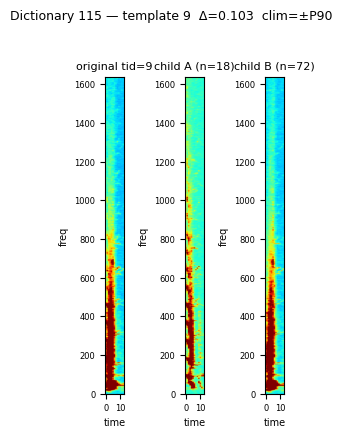

In [5]:
# Shared clim across the three unit templates for fair comparison.
orig_u = unit_l2(base)
a_u = unit_l2(result.template_a)
b_u = unit_l2(result.template_b)
shared_lim = clim_pm_p90(np.concatenate([orig_u.ravel(), a_u.ravel(), b_u.ravel()]))

fig, axes = plt.subplots(1, 3, figsize=(3 * PANEL_W, PANEL_H))
show_spec(axes[0], orig_u, f"original tid={template_id}", lim=shared_lim)
show_spec(axes[1], a_u, f"child A (n={na})", lim=shared_lim)
show_spec(axes[2], b_u, f"child B (n={nb})", lim=shared_lim)
fig.suptitle(
    f"Dictionary {dictionary_id} — template {template_id}  "
    f"Δ={result.relative_reduction:.3f}  clim=±P90",
    fontsize=9,
    y=1.02,
)
fig.tight_layout()
plt.show()


## Child A — template and its patches

### Child A — template + 18 patches

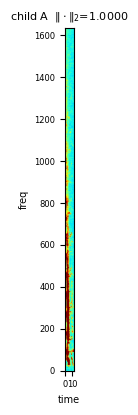

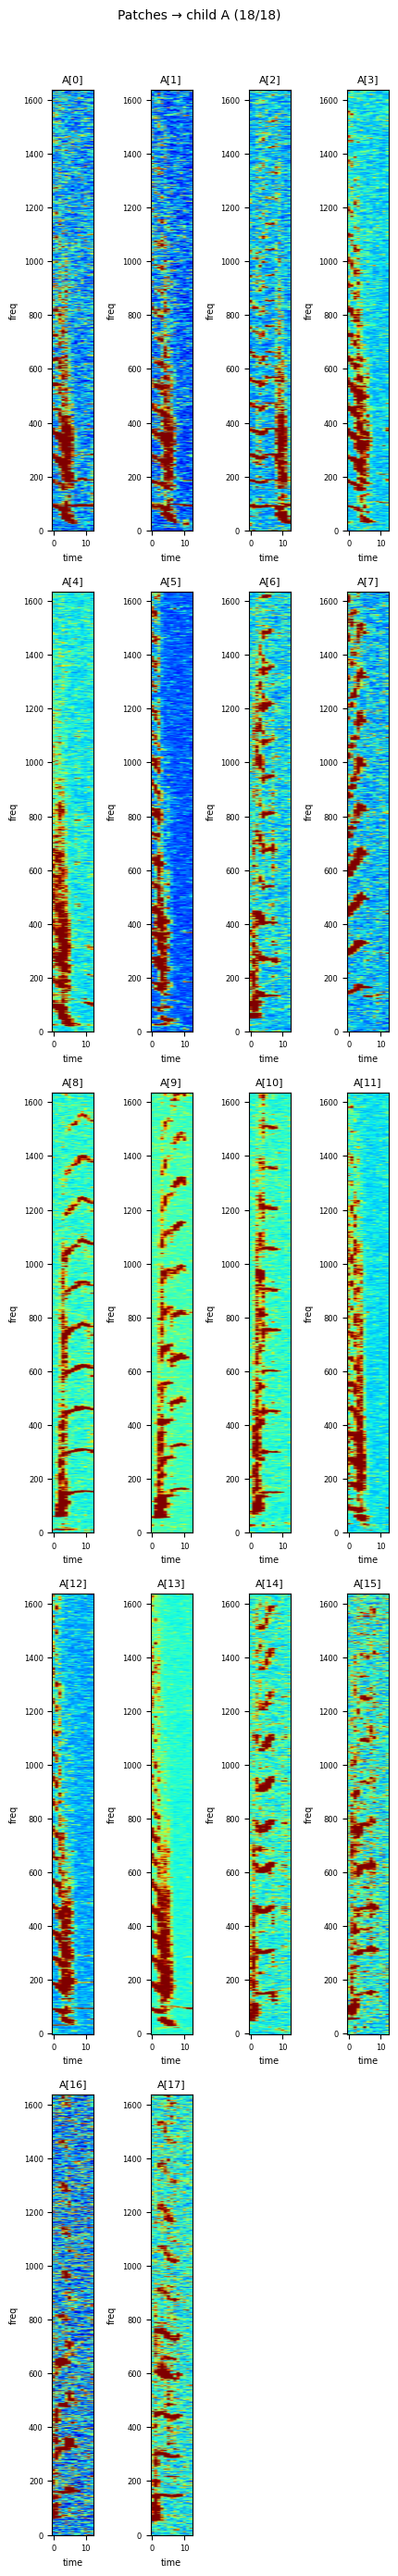

In [6]:
show_child_with_patches(result.template_a, result.patches_a, "A")


## Child B — template and its patches


### Child B — template + 72 patches

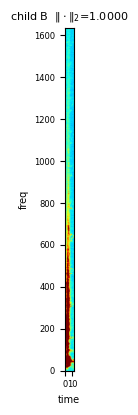



In [7]:
show_child_with_patches(result.template_b, result.patches_b, "B")


## Optional: scan every template in the dictionary

Runs `run_split` for each template with enough patches and plots original | A | B.


 tid     n      rel          SSE1          SSE2   nA   nB  trial
--------------------------------------------------------------------
   0    28    0.326     1.415e+07     9.536e+06   15   13      0


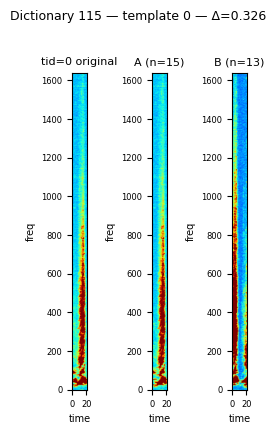

   1    16    0.275     7.444e+06     5.396e+06    6   10      0


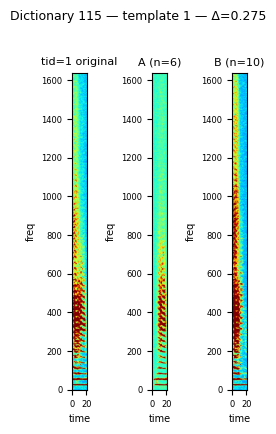

   3    24    0.185     2.165e+07     1.764e+07   15    9      6


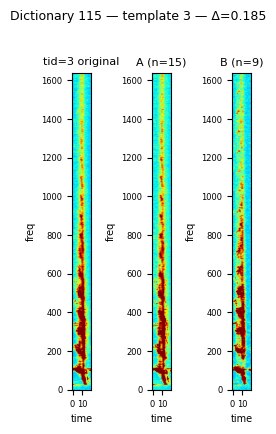

   4    12    0.341     2.435e+06     1.606e+06    4    8      0


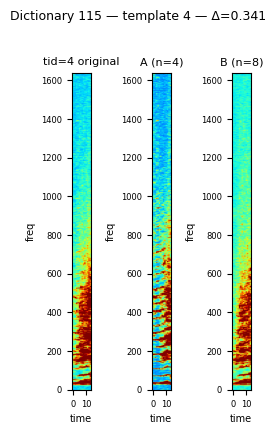

   6    31    0.136     3.271e+06     2.827e+06   20   11      7


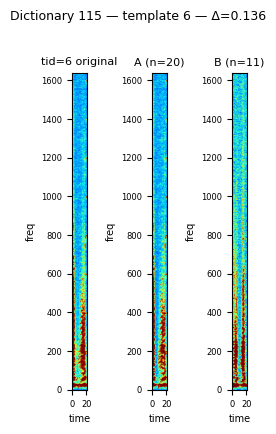

   7     6    0.230     2.076e+06     1.599e+06    3    3      4


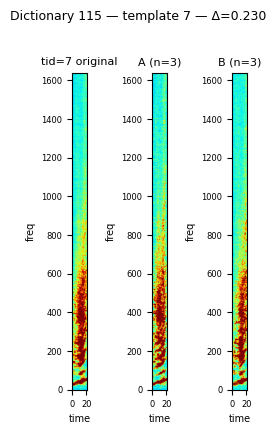

   8    38    0.153     3.918e+06     3.318e+06   21   17     16


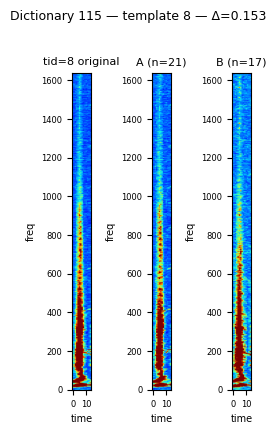

   9    90    0.103     1.808e+07     1.623e+07   18   72     18


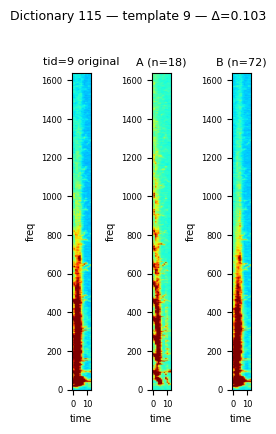

  10    53    0.126      1.08e+07     9.441e+06    9   44     11


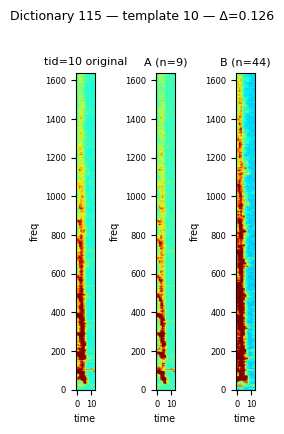

  11     4    0.695     5.599e+05     1.709e+05    2    2      2


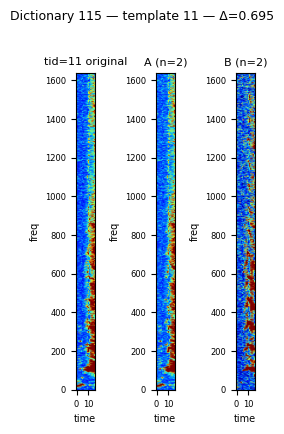

  12    77    0.130     5.487e+06     4.771e+06   11   66      1


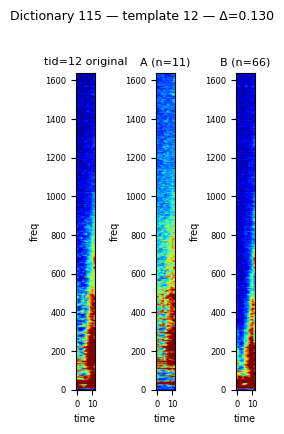

  13     6    0.337     1.203e+06     7.975e+05    3    3      0


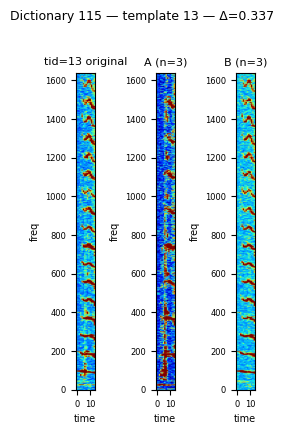

  14     4    0.556     4.574e+05      2.03e+05    2    2     12


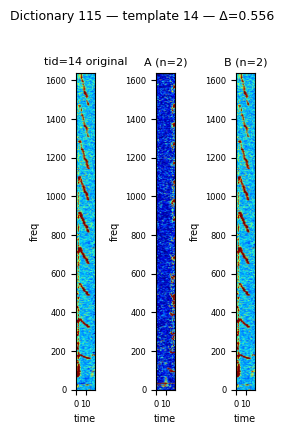

  15     2  —    (too few patches)


In [8]:
with closing(catalog.connect(DB_PATH, read_only=True)) as conn:
    all_rows = conn.execute(
        """
        SELECT m.window_id, m.t_start, m.amplitude, t.template_id
        FROM matchings m
        JOIN templates t ON t.template_pk = m.template_pk
        WHERE m.dictionary_id = ?
        """,
        (dictionary_id,),
    ).fetchall()

all_matchings = [
    Matching(
        template_id=int(r["template_id"]),
        window_id=str(r["window_id"]),
        t_start=int(r["t_start"]),
        amplitude=float(r["amplitude"] if r["amplitude"] is not None else 1.0),
    )
    for r in all_rows
]

print(f"{'tid':>4}  {'n':>4}  {'rel':>7}  {'SSE1':>12}  {'SSE2':>12}  {'nA':>3}  {'nB':>3}  {'trial':>5}")
print("-" * 68)

for tid in dictionary.order:
    tmpl = dictionary.templates[tid]
    m_tid = [m for m in all_matchings if m.template_id == tid]
    if len(m_tid) < 2 * MIN_SIZE:
        print(f"{tid:4d}  {len(m_tid):4d}  —    (too few patches)")
        continue
    p_tid = _extract_patches(
        stack, m_tid, width=int(tmpl.width), n_freq=int(tmpl.n_freq)
    )
    if len(p_tid) < 2 * MIN_SIZE:
        print(f"{tid:4d}  {len(p_tid):4d}  —    (too few extractable patches)")
        continue
    base_t = tmpl.as_rank1 if tmpl.n_components == 1 else tmpl.basis[0]
    try:
        res = run_split(
            p_tid,
            np.asarray(base_t, dtype=np.float64),
            n_trials=N_TRIALS,
            n_refine=N_REFINE,
            epsilon=EPSILON,
            min_size=MIN_SIZE,
            seed=RNG_SEED,
        )
    except ValueError as exc:
        print(f"{tid:4d}  {len(p_tid):4d}  —    ({exc})")
        continue

    print(
        f"{tid:4d}  {len(p_tid):4d}  {res.relative_reduction:7.3f}  "
        f"{res.sse_one:12.4g}  {res.sse_two:12.4g}  "
        f"{len(res.patches_a):3d}  {len(res.patches_b):3d}  {res.best_trial:5d}"
    )

    o_u = unit_l2(base_t)
    a_u = unit_l2(res.template_a)
    b_u = unit_l2(res.template_b)
    lim = clim_pm_p90(np.concatenate([o_u.ravel(), a_u.ravel(), b_u.ravel()]))
    fig, axes = plt.subplots(1, 3, figsize=(3 * PANEL_W, PANEL_H))
    show_spec(axes[0], o_u, f"tid={tid} original", lim=lim)
    show_spec(axes[1], a_u, f"A (n={len(res.patches_a)})", lim=lim)
    show_spec(axes[2], b_u, f"B (n={len(res.patches_b)})", lim=lim)
    fig.suptitle(
        f"Dictionary {dictionary_id} — template {tid} — Δ={res.relative_reduction:.3f}",
        fontsize=9,
        y=1.01,
    )
    fig.tight_layout()
    plt.show()
